# Datarydding

In [1]:
import pandas as pd
from pathlib import Path

## Bysykkel

Startar med bysykkel-data. 

In [2]:
# Mappa der CSV-filene ligg
data_mappe = Path("data/rådata/bysykkel")

# Finn alle csv-filer og sorter dei kronologisk
csv_filer = sorted(data_mappe.glob("*.csv"))

# Les inn alle filene og slå dei saman til éin DataFrame
bysykkel = pd.concat(
    (pd.read_csv(f) for f in csv_filer),
    ignore_index=True,
)

print(f"Lasta inn {len(csv_filer)} filer. Totalt {len(bysykkel)} rader.")

Lasta inn 100 filer. Totalt 4664902 rader.


Sjekkar korleis ting ser ut:

In [3]:
bysykkel.head()

,started_at,ended_at,duration,start_station_id,start_station_name,start_station_description,start_station_latitude,start_station_longitude,end_station_id,end_station_name,end_station_description,end_station_latitude,end_station_longitude
0,2018-06-29 10:45:12.736000+00:00,2018-06-29 11:05:10.430000+00:00,1197,3,Grieghallen,,60.388167,5.328335,83,Bergen jernbanestasjon,,60.390324,5.332440
1,2018-06-29 10:53:59.691000+00:00,2018-06-29 11:11:28.184000+00:00,1048,49,Studentsenteret UIB,,60.387198,5.322980,75,Akvariet,,60.399877,5.304686
2,2018-06-29 11:01:02.987000+00:00,2018-06-29 11:09:13.172000+00:00,490,58,Tårnplass,,60.393755,5.321792,157,Høyteknologisenteret,Høyteknologisenteret,60.382255,5.332332
3,2018-06-29 11:30:33.362000+00:00,2018-06-29 11:38:32.276000+00:00,478,157,Høyteknologisenteret,Høyteknologisenteret,60.382255,5.332332,83,Bergen jernbanestasjon,,60.390324,5.332440
4,2018-06-29 11:40:44.376000+00:00,2018-06-29 12:10:23.766000+00:00,1779,58,Tårnplass,,60.393755,5.321792,116,Lysverket,"Gamle lysverket, ved KODE",60.389543,5.329622


Lagrar til ei csv-fil for å gjera ting lettare seinare

In [4]:
# tek vare på starttid og varighet (resten treng me ikkje no)
bysykkel[["started_at", "duration"]].to_csv("data/bysykkel.csv", index=False)

Les inn den nye fila og fiksar tid

In [5]:
bysykkel = pd.read_csv("data/bysykkel.csv")

bysykkel["started_at"] = pd.to_datetime(
    bysykkel["started_at"], utc=True, format="ISO8601"
)

print(bysykkel["started_at"].dtype)  # skal vere datetime64[..., UTC]

datetime64[us, UTC]


sjekkar kor korte/lange turane er. 

In [6]:
# Kor lange er turane? duration er i sekund.
print(bysykkel["duration"].describe())
print("Under 1 minutt:", (bysykkel["duration"] < 60).sum())
print("Over 3 timar:", (bysykkel["duration"] > 3 * 3600).sum())

count    4.664902e+06
mean     6.359236e+02
std      1.926209e+03
min      0.000000e+00
25%      3.090000e+02
50%      4.720000e+02
75%      7.140000e+02
max      1.288927e+06
Name: duration, dtype: float64
Under 1 minutt: 436
Over 3 timar: 2768


Fjernar urimelege turar

In [7]:
# Under 1 minutt. Over 3 timar.
rimeleg = bysykkel["duration"].between(60, 3 * 3600)
print(f"Fjernar {(~rimeleg).sum()} av {len(bysykkel)} turar")
bysykkel = bysykkel[rimeleg]

Fjernar 3204 av 4664902 turar


Er kun interessert i turar per time seinare. Fiksar tid og tel opp

In [8]:
# Gjer starttida til indeks og tel turar i kvar time (i UTC).
# resample lagar ei rad for kvar time, også timar utan turar (dei får 0).
turar_per_time = bysykkel.set_index("started_at").resample("h").size()
print(turar_per_time.head())
print("Timar totalt:", len(turar_per_time))
print("Timar med 0 turar:", (turar_per_time == 0).sum())

started_at
2018-06-29 10:00:00+00:00     2
2018-06-29 11:00:00+00:00     6
2018-06-29 12:00:00+00:00    20
2018-06-29 13:00:00+00:00    37
2018-06-29 14:00:00+00:00    40
Freq: h, dtype: int64
Timar totalt: 72372
Timar med 0 turar: 15417


In [9]:
turar_per_time.to_frame("turar").to_csv("data/turar_per_time.csv")

In [10]:
turar_per_time = pd.read_csv("data/turar_per_time.csv", index_col=0)["turar"]
turar_per_time.index = pd.to_datetime(turar_per_time.index, utc=True)
turar_per_time.head()

started_at
2018-06-29 10:00:00+00:00     2
2018-06-29 11:00:00+00:00     6
2018-06-29 12:00:00+00:00    20
2018-06-29 13:00:00+00:00    37
2018-06-29 14:00:00+00:00    40
Name: turar, dtype: int64

## Vêrdata

Same framgangsmåte men litt anna rådataformat

In [11]:
data_mappe = Path("data/rådata/ver")
csv_filer = sorted(data_mappe.glob("*.csv"))

dfs = []
for f in csv_filer:
    df_tmp = pd.read_csv(
        f,
        sep=";",
        decimal=",",
        na_values="-",      # seklima skriv "-" når ein verdi manglar
        skipfooter=1,       # siste linja er ein lisenstekst
        encoding="utf-8",
        engine="python",
    )
    dfs.append(df_tmp)

ver = pd.concat(dfs, ignore_index=True)
print(f"Lasta inn {len(csv_filer)} filer. Totalt {len(ver)} rader.")

Lasta inn 4 filer. Totalt 72384 rader.


Fiksar litt på namn, og tek vek stasjonsnamn, id og vindkast

In [12]:
ver = ver.rename(columns={
    "Tid(norsk normaltid)": "tid",
    "Lufttemperatur": "temp",
    "Middelvind": "vind",
    "Nedbør (1 t)": "nedbor",
    "Høyeste vindkast (1 t)": "vindkast",
})

# Navn og Stasjon er like i alle rader. Vindkast er ikkje med i modellen.
ver = ver.drop(columns=["Navn", "Stasjon", "vindkast"])

Gjer om tid til UTC. Sjekkar at det ikkje er dublettar. 

In [13]:
ver["tid"] = pd.to_datetime(ver["tid"], format="%d.%m.%Y %H:%M")

# Norsk normaltid er UTC+1 heile året. Trekk frå éin time og merk som UTC.
ver["tid"] = (ver["tid"] - pd.Timedelta(hours=1)).dt.tz_localize("UTC")

ver = ver.set_index("tid").sort_index()
print("Dublettar:", ver.index.duplicated().sum())

Dublettar: 0


Fjernar støy (finns nokre negative nedbørsverdiar)

In [14]:
# Nedbør kan ikkje vere negativ (målestøy). Set til 0.
print("Negativ nedbør:", (ver["nedbor"] < 0).sum(), "timar")
ver["nedbor"] = ver["nedbor"].clip(lower=0)

Negativ nedbør: 17 timar


Fyller korte hol i vinddataa og lokaliserer store hol

In [15]:
# Finn sammenhengande hol og kor lange dei er
mangel = ver["vind"].isna()
hol_id = (mangel != mangel.shift()).cumsum()
lengd = mangel.groupby(hol_id).transform("sum")

# Interpoler berre hol på 1–3 timar. Lange hol blir ståande som NaN.
kort_hol = mangel & (lengd <= 3)
ver.loc[kort_hol, "vind"] = ver["vind"].interpolate()[kort_hol]
print("Fylte timar:", kort_hol.sum())

# Hola som står att (blir fjerna ved samanslåing)
mangel = ver["vind"].isna()
hol_id = (mangel != mangel.shift()).cumsum()
print(ver.index.to_series()[mangel].groupby(hol_id[mangel]).agg(["min", "max", "count"]))
print(ver.isna().sum())

Fylte timar: 33
                           min                       max  count
vind                                                           
2    2024-06-25 15:00:00+00:00 2024-06-27 09:00:00+00:00     43
4    2025-02-21 11:00:00+00:00 2025-03-14 14:00:00+00:00    508
temp        0
vind      551
nedbor      2
dtype: int64


In [16]:
# lagrar
ver.to_csv("data/ver_rydda.csv")

## Plott og utforsking


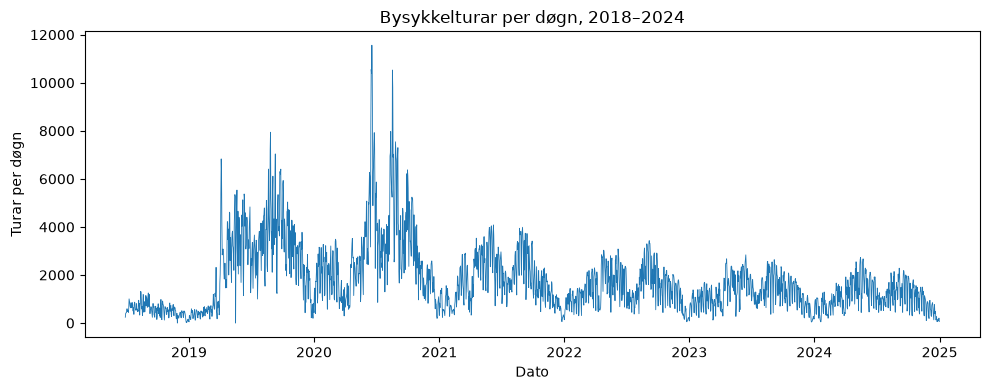

In [17]:
import matplotlib.pyplot as plt

Path("figurar").mkdir(exist_ok=True)

# Norsk tid i plotta, så døgna startar ved midnatt her
lokal = turar_per_time.tz_convert("Europe/Oslo")
lokal = lokal[lokal.index.year <= 2024]  # ikkje kikk på teståret

per_dogn = lokal.resample("D").sum()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(per_dogn.index, per_dogn.values, linewidth=0.6)
ax.set(title="Bysykkelturar per døgn, 2018–2024",
       xlabel="Dato", ylabel="Turar per døgn")
fig.tight_layout()
fig.savefig("figurar/turar_per_dogn.png", dpi=150)
plt.show()

In [18]:
print("Døgn med 0 turar:", (per_dogn == 0).sum())
print(per_dogn[per_dogn < 50])

Døgn med 0 turar: 2
started_at
2018-11-28 00:00:00+01:00     0
2018-12-24 00:00:00+01:00    22
2018-12-26 00:00:00+01:00    36
2019-01-01 00:00:00+01:00    49
2019-05-17 00:00:00+02:00     0
2023-12-24 00:00:00+01:00    42
2024-01-20 00:00:00+01:00    48
Name: turar, dtype: int64


In [19]:
# Kva lokalt døgn tilhøyrer kvar time?
lokal_dogn = turar_per_time.index.tz_convert("Europe/Oslo").normalize()

# Døgn der summen er 0: tenesta var stengd
dogn_sum = turar_per_time.groupby(lokal_dogn).transform("sum")
stengt = dogn_sum == 0
print("Fjernar", lokal_dogn[stengt].nunique(), "døgn,", stengt.sum(), "timar")

turar_per_time = turar_per_time[~stengt]
turar_per_time.to_frame("turar").to_csv("data/turar_per_time.csv")

Fjernar 2 døgn, 48 timar


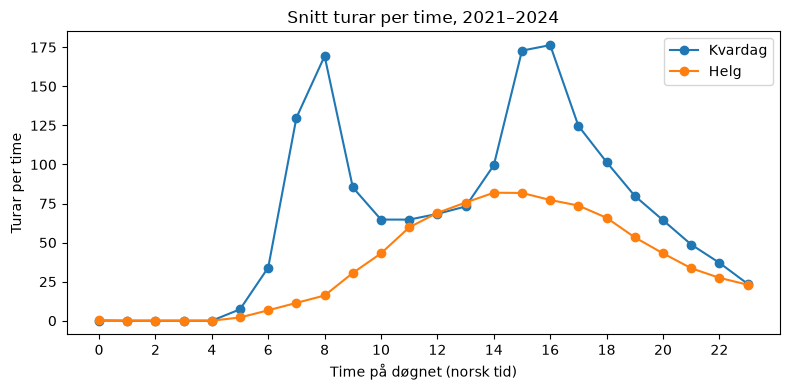

In [20]:
# Norsk tid, 2021–2024 (same regime som vi skal trene på, utan teståret)
lokal = turar_per_time.tz_convert("Europe/Oslo")
lokal = lokal[(lokal.index.year >= 2021) & (lokal.index.year <= 2024)]

helg = lokal.index.dayofweek >= 5  # laurdag = 5, søndag = 6
kvardag_snitt = lokal[~helg].groupby(lokal.index[~helg].hour).mean()
helg_snitt = lokal[helg].groupby(lokal.index[helg].hour).mean()

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(kvardag_snitt.index, kvardag_snitt.values, marker="o", label="Kvardag")
ax.plot(helg_snitt.index, helg_snitt.values, marker="o", label="Helg")
ax.set(title="Snitt turar per time, 2021–2024",
       xlabel="Time på døgnet (norsk tid)", ylabel="Turar per time")
ax.set_xticks(range(0, 24, 2))
ax.legend()
fig.tight_layout()
fig.savefig("figurar/turar_per_time_kvardag_helg.png", dpi=150)
plt.show()

In [21]:
# Les inn det rydda vêret
ver = pd.read_csv("data/ver_rydda.csv", index_col="tid")
ver.index = pd.to_datetime(ver.index, utc=True)

# Nedbør stempla T gjeld timen før T. Turtimen H dekkjer H til H+1,
# så han skal ha nedbøren stempla H+1. shift(-1) hentar verdien frå timen etter.
ver["nedbor"] = ver["nedbor"].shift(-1)

# Slå saman på UTC-tid. join behald alle turtimar og hentar vêret for same time.
df = turar_per_time.to_frame("turar").join(ver)

# Fjern timar utan vêr (dei lange vindhola og nokre få andre)
manglar = df[["temp", "vind", "nedbor"]].isna().any(axis=1)
print("Fjernar", manglar.sum(), "timar utan vêr")
df = df[~manglar]

print(df.head())
print("Timar:", len(df), "frå", df.index.min(), "til", df.index.max())

Fjernar 553 timar utan vêr
                           turar  temp  vind  nedbor
started_at                                          
2018-06-29 10:00:00+00:00      2  19.9   5.5     0.0
2018-06-29 11:00:00+00:00      6  21.0   6.4     0.0
2018-06-29 12:00:00+00:00     20  22.4   6.4     0.0
2018-06-29 13:00:00+00:00     37  22.4   6.4     0.0
2018-06-29 14:00:00+00:00     40  22.0   7.3     0.0
Timar: 71771 frå 2018-06-29 10:00:00+00:00 til 2026-09-30 21:00:00+00:00


In [22]:
# Opningstid kl. 05–24 (norsk tid). Timane 00–04 er stengt, så 0 turar der er ikkje etterspurnad.
lokal_time = df.index.tz_convert("Europe/Oslo").hour
print("Fjernar", (lokal_time < 5).sum(), "nattetimar")
df = df[lokal_time >= 5]

Fjernar 14950 nattetimar


In [23]:
df.index.name = "tid"
df.to_csv("data/timetabell.csv")
print(len(df), "timar lagra")

56821 timar lagra


            snitt turar  timar
regnklasse                    
0                  83.7  20371
0,1–0,5            56.3   3783
0,6–1              44.8   1316
1,1–2              37.6   1190
2,1–4              34.4    750
over 4             33.0    316


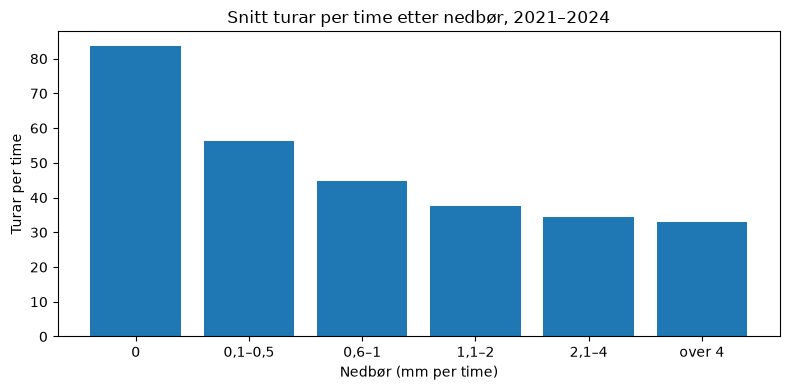

In [24]:
# 2021–2024, same periode som før
lokal = df.copy()
lokal.index = lokal.index.tz_convert("Europe/Oslo")
lokal = lokal[(lokal.index.year >= 2021) & (lokal.index.year <= 2024)]

# Del nedbøren inn i klassar
klassar = [-0.01, 0, 0.5, 1, 2, 4, 50]
namn = ["0", "0,1–0,5", "0,6–1", "1,1–2", "2,1–4", "over 4"]
lokal["regnklasse"] = pd.cut(lokal["nedbor"], bins=klassar, labels=namn)

snitt = lokal.groupby("regnklasse", observed=True)["turar"].mean()
antal = lokal.groupby("regnklasse", observed=True)["turar"].size()
print(pd.DataFrame({"snitt turar": snitt.round(1), "timar": antal}))

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(snitt.index.astype(str), snitt.values)
ax.set(title="Snitt turar per time etter nedbør, 2021–2024",
       xlabel="Nedbør (mm per time)", ylabel="Turar per time")
fig.tight_layout()
fig.savefig("figurar/turar_mot_nedbor.png", dpi=150)
plt.show()